# Iterative Closest Point

Estimate a planar rigid transform between two point clouds when point correspondences are initially unknown.

Each iteration pairs transformed source points with their nearest target points and fits an orientation-preserving least-squares rigid transform by singular value decomposition. The updates compose in the same coordinate convention. The experiment has a known ground-truth rotation and translation.

In [1]:
from pathlib import Path
import sys

here = Path.cwd()
sys.path.insert(0, str(here.parent))
import numpy as np
import matplotlib.pyplot as plt

from estimation import icp, rotation

## Register an asymmetric shape

The fixture uses irregularly spaced points along an L and an arc. Source order is shuffled so row correspondence cannot help the estimator.

Point-to-set RMS 0.00204 | translation error 0.00009 | iterations 8


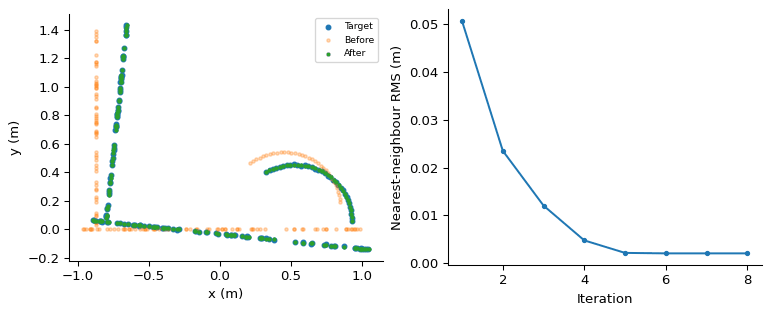

In [2]:
rng = np.random.default_rng(29)
edge = rng.uniform(-1, 1, 75)
alt = rng.uniform(0, 1.4, 55)
angles = np.linspace(0.1, 2.2, 34)
source = np.vstack(
    [
        np.c_[edge, np.zeros_like(edge)],
        np.c_[np.full_like(alt, -0.87), alt],
        np.c_[0.45 + 0.4 * np.cos(angles), 0.15 + 0.39 * np.sin(angles)],
    ]
)
R0 = rotation(0.105)
t0 = np.array([0.065, -0.04])
target = source @ R0 + t0 + rng.normal(0, 0.0015, source.shape)
source = source[rng.permutation(len(source))]
aligned, R, t, err = icp(source, target)
assert np.isclose(np.linalg.det(R), 1) and np.allclose(aligned, source @ R + t)
assert err[-1] < 0.01 and np.all(np.diff(err) < 1e-8)
print(
    f"Point-to-set RMS {err[-1]:.5f} | translation error {np.linalg.norm(t-t0):.5f} | iterations {len(err)}"
)
fig, (a, b) = plt.subplots(1, 2, figsize=(8, 3.2), constrained_layout=True)
a.scatter(*target.T, s=12, label="Target")
a.scatter(*source.T, s=6, alpha=0.3, label="Before")
a.scatter(*aligned.T, s=5, label="After")
a.set(aspect="equal", xlabel="x (m)", ylabel="y (m)")
a.legend(fontsize=7)
b.plot(np.arange(1, len(err) + 1), err, ".-")
b.set(xlabel="Iteration", ylabel="Nearest-neighbour RMS (m)")
plt.show()

## Interpreting the result

ICP is a local method. A distant initial pose or a symmetric object can produce a plausible residual at an incorrect registration.

## Exercise

Increase the initial rotation until the point error and recovered rotation tell different stories.

## References

[Besl and McKay, A Method for Registration of 3-D Shapes (1992)](https://doi.org/10.1109/34.121791)